# Predicting US Flight Delays 
**Dataset:** USDOT 2015 Flight Delays (Kaggle), read from HDFS.
Target: **is_delayed = ARRIVAL_DELAY > 15** (binary classification)

## 1) Démarrage de Spark [switch to english]

In [1]:
import os
# Hadoop 3.3.4 (bundled with PySpark 3.5) crashes on Java 23+ ("getSubject is not supported"): force Java 17
os.environ["JAVA_HOME"] = "/opt/homebrew/opt/openjdk@17"

from pyspark.sql import SparkSession, functions as F
spark = (SparkSession.builder.appName("flight-delays")
         .config("spark.driver.memory", "4g")
         # HDFS dans Docker : joindre les DataNodes par hostname (cf. /etc/hosts)
         .config("spark.hadoop.dfs.client.use.datanode.hostname", "true")
         .getOrCreate())
spark

26/11/19 08:55:58 WARN Utils: Your hostname, MacBook-Air-de-Jimi.local resolves to a loopback address: 127.0.0.1; using 10.184.31.222 instead (on interface en0)
26/11/19 08:55:58 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/19 08:55:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/19 08:55:59 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


## 2) Lecture depuis HDFS [switch to english]

In [3]:
raw = spark.read.csv(
    "hdfs://localhost:9000/data/raw/flights.csv", header=True)

print("Rows:", raw.count())
print("Columns:", len(raw.columns))

Rows: 5819079
Columns: 31


Here how do we say we constate that we have 5m lines and cols amd whatever nice makrup way 

## 3) EDA

In [4]:
#raw.show(5, vertical=True)
raw.limit(5).toPandas()
#raw.printSchema() 
#same as df.info()

26/11/19 08:57:57 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,0005,...,0408,-22,0,0,None,None,None,None,None,None
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,0010,...,0741,-9,0,0,None,None,None,None,None,None
2,2015,1,1,4,US,840,N171US,SFO,CLT,0020,...,0811,5,0,0,None,None,None,None,None,None
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,0020,...,0756,-9,0,0,None,None,None,None,None,None
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,0025,...,0259,-21,0,0,None,None,None,None,None,None


## 3.1) Création de l'échantillon d'exploration (EDA) & Valeurs manquantes

In [5]:
eda_sample = raw.sample(fraction=0.05, seed=42).cache()
print("Sample size:", eda_sample.count())

Sample size: 290686


### Observations initiales sur les données brutes (EDA) [SWITCH TO ENGLISH]
* **Volume :** 5 819 079 vols répartis sur 31 colonnes.

* **Sémantique métier identifiée :**
  * Les retards négatifs (ex: `ARRIVAL_DELAY = -22`) indiquent un vol arrivé **en avance**.
  * Les heures sont encodées au format entier `HHMM` (ex: `0005` pour 00h05).
  * Les valeurs `NULL` dans les colonnes de causes de retard (`WEATHER_DELAY`, `CANCELLATION_REASON`, etc.) sont normales : elles ne sont renseignées que lorsqu'un retard significatif (> 15 min) ou une annulation survient.
  * **Format des types :**
* Par défaut, Spark charge toutes les colonnes en `string` (texte) pour éviter une double lecture coûteuse du fichier CSV. Une conversion explicite (`cast`) vers `double` est nécessaire avant tout calcul statistique ou entraînement ML.

In [6]:
import pandas as pd
null_exprs = [F.sum(F.isnull(c).cast("int")).alias(c) for c in eda_sample.columns]
counts = eda_sample.select(null_exprs).first().asDict()

pd.Series(counts, name="missing").sort_values(ascending=False)

#another way to do it
# missing_counts = eda_sample.select(
#     [F.sum(F.col(c).isNull().cast("int")).alias(c) for c in eda_sample.columns]
# )
# missing_counts.toPandas().T.rename(columns={0: "missing"}).sort_values("missing", ascending=False)

CANCELLATION_REASON    286290
WEATHER_DELAY          237598
LATE_AIRCRAFT_DELAY    237598
AIRLINE_DELAY          237598
SECURITY_DELAY         237598
AIR_SYSTEM_DELAY       237598
AIR_TIME                 5148
ARRIVAL_DELAY            5148
ELAPSED_TIME             5148
WHEELS_ON                4542
TAXI_IN                  4542
ARRIVAL_TIME             4542
TAXI_OUT                 4357
WHEELS_OFF               4357
DEPARTURE_DELAY          4224
DEPARTURE_TIME           4224
TAIL_NUMBER               734
SCHEDULED_DEPARTURE         0
CANCELLED                   0
DAY                         0
DAY_OF_WEEK                 0
AIRLINE                     0
FLIGHT_NUMBER               0
SCHEDULED_ARRIVAL           0
DIVERTED                    0
ORIGIN_AIRPORT              0
DISTANCE                    0
DESTINATION_AIRPORT         0
MONTH                       0
SCHEDULED_TIME              0
YEAR                        0
Name: missing, dtype: int64

The missing values are **not random data corruption**they follow exact structural patterns tied to flight outcomes:

1. All pre-departure features (`MONTH`, `DAY_OF_WEEK`, `AIRLINE`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `SCHEDULED_DEPARTURE`, `SCHEDULED_TIME`, `DISTANCE`) are **100% complete** and require no imputation.
2. The `5,234` missing values in `ARRIVAL_DELAY`, `ELAPSED_TIME`, and `AIR_TIME` match the exact sum of **cancelled flights** (~4,400, where `CANCELLATION_REASON` is populated) and **diverted flights** (~800, where `DEPARTURE_TIME` exists but `ARRIVAL_TIME` does not). Filtering out `CANCELLED == 1` and `DIVERTED == 1` cleanly eliminates all missing target labels.
3. **Structural Nulls in Delay Causes (`237,966` nulls across all 5 `*_DELAY` columns):** ~82% of flights were not significantly delayed (`ARRIVAL_DELAY < 15`), so no delay cause was recorded. Since these columns are both sparse and represent post-flight leakage, they are dropped.

## 3.2) Feature Selection & Data Leakage Verification

### Initial Manual Exploration
After reviewing the dataset schema and domain meaning of all 31 columns, we separated the features into two groups:

* **Safe Features (Known before takeoff):** `MONTH`, `DAY_OF_WEEK`, `AIRLINE`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `SCHEDULED_DEPARTURE`, `SCHEDULED_TIME`, `DISTANCE`. *(Note: `TAIL_NUMBER`, `FLIGHT_NUMBER`, and `DAY` are excluded to prevent overfitting/high cardinality, and `SCHEDULED_ARRIVAL` is redundant with departure + duration).*
* **Dropped Columns (Post-takeoff / Data Leakage):** `DEPARTURE_TIME`, `DEPARTURE_DELAY`, `TAXI_OUT`, `WHEELS_OFF`, `WHEELS_ON`, `TAXI_IN`, `ARRIVAL_TIME`, `ELAPSED_TIME`, `AIR_TIME`, `CANCELLATION_REASON`, and the 5 specific delay breakdown columns (`AIR_SYSTEM_DELAY`, `SECURITY_DELAY`, `AIRLINE_DELAY`, `LATE_AIRCRAFT_DELAY`, `WEATHER_DELAY`). Including these would leak future information that does not exist when predicting a delay prior to departure. *(Note: `CANCELLED`, `DIVERTED`, and `ARRIVAL_DELAY` are kept temporarily only to filter invalid flights and create our target label, then removed before training).*

### Proving Data Leakage in the Delay Columns
According to the dataset documentation, the 5 specific delay columns are only populated when a flight is delayed by 15 minutes or more, and **their sum equals the exact `ARRIVAL_DELAY`**. To prove this empirically before dropping them, we sum those 5 columns together and compare the result side-by-side against `ARRIVAL_DELAY`.

In [8]:
delay_cols = ["AIR_SYSTEM_DELAY", "SECURITY_DELAY", "AIRLINE_DELAY", 
              "LATE_AIRCRAFT_DELAY", "WEATHER_DELAY"]

# Step 1: Fill empty cells with "0"
temp = eda_sample.fillna("0", subset=delay_cols)

# Step 2: Add the 5 delay columns together
total_causes = (
    F.col("AIR_SYSTEM_DELAY").cast("double") +
    F.col("SECURITY_DELAY").cast("double") +
    F.col("AIRLINE_DELAY").cast("double") +
    F.col("LATE_AIRCRAFT_DELAY").cast("double") +
    F.col("WEATHER_DELAY").cast("double")
)

# Step 3: Compare actual ARRIVAL_DELAY vs. the sum of the 5 causes
check = temp.select(
    F.col("ARRIVAL_DELAY").cast("double"),
    total_causes.alias("sum_causes")
).filter(F.col("ARRIVAL_DELAY") >= 15)

check.show(10)

+-------------+----------+
|ARRIVAL_DELAY|sum_causes|
+-------------+----------+
|         18.0|      18.0|
|         22.0|      22.0|
|         20.0|      20.0|
|         16.0|      16.0|
|         29.0|      29.0|
|         26.0|      26.0|
|         21.0|      21.0|
|         72.0|      72.0|
|         26.0|      26.0|
|         29.0|      29.0|
+-------------+----------+
only showing top 10 rows



## Data Quality Checks (Known Dataset Anomalies)

Based on the Kaggle dataset documentation, two known formatting quirks exist in the 2015 flight records:
1. **Numeric Airport Codes:** In October 2015, the DOT temporarily replaced 3-letter IATA airport codes (e.g., `JFK`) with 5-digit numeric IDs (e.g., `12478`).
2. **Midnight as `2400`:** Some midnight departures are encoded as `2400` instead of `0000`, which would create a invalid hour `24` when extracting departure hours.

We check whether both anomalies appear in our sample before cleaning them.

In [9]:
# 1. Check for numeric airport codes (if text turns into a valid integer, it's numeric)
num_origin = eda_sample.filter(F.col("ORIGIN_AIRPORT").cast("int").isNotNull()).count()
num_dest   = eda_sample.filter(F.col("DESTINATION_AIRPORT").cast("int").isNotNull()).count()

# midnight flights written as 2400
midnight_2400 = eda_sample.filter(F.col("SCHEDULED_DEPARTURE") == "2400").count()

print("Numeric airports -> Origin:", num_origin, "| Dest:", num_dest)
print("Midnight 2400 departures:", midnight_2400)

Numeric airports -> Origin: 24312 | Dest: 24312
Midnight 2400 departures: 0


In [10]:
%pip install matplotlib

/Users/jimi/Desktop/Projet HDFS/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


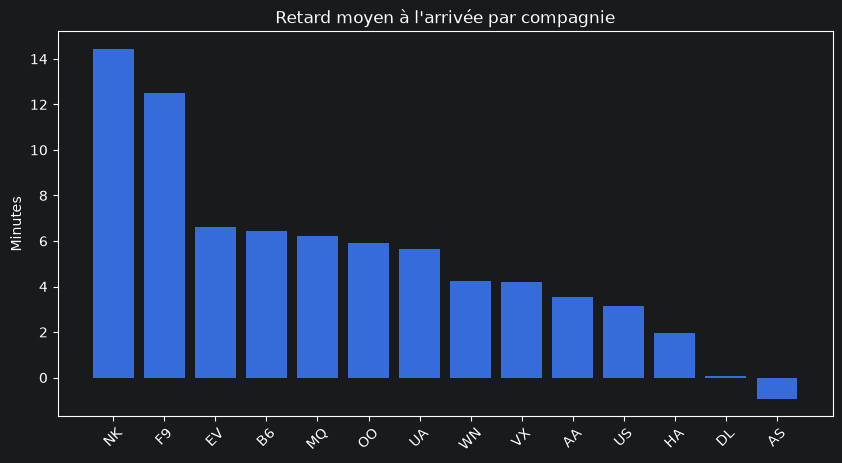

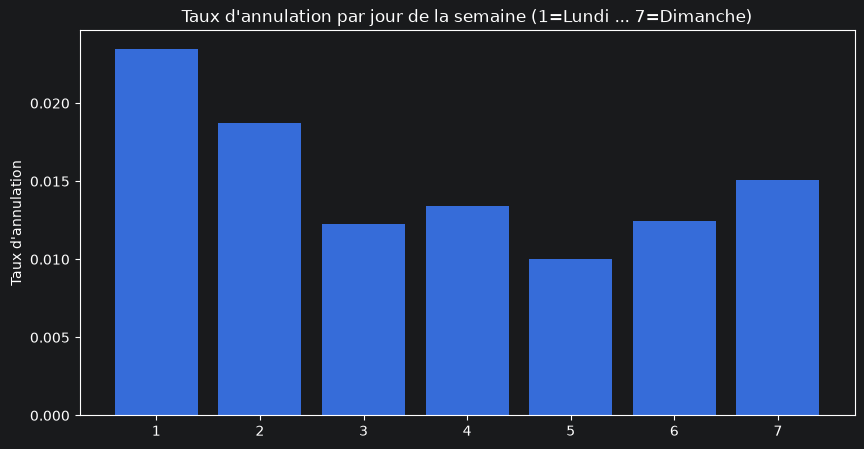

In [11]:
import matplotlib.pyplot as plt

pdf = eda_sample.select(
    "AIRLINE", "DAY_OF_WEEK", "MONTH", "CANCELLED", "ARRIVAL_DELAY"
).toPandas()

pdf["CANCELLED"] = pdf["CANCELLED"].astype(float)
pdf["ARRIVAL_DELAY"] = pdf["ARRIVAL_DELAY"].astype(float)

# Graphique 1 : Retard moyen par compagnie
delay_by_airline = pdf.groupby("AIRLINE")["ARRIVAL_DELAY"].mean().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
plt.bar(delay_by_airline.index, delay_by_airline.values)
plt.title("Retard moyen à l'arrivée par compagnie")
plt.ylabel("Minutes")
plt.xticks(rotation=45)
plt.show()

# Graphique 2 : Taux d'annulation par jour de la semaine
cancel_by_day = pdf.groupby("DAY_OF_WEEK")["CANCELLED"].mean()
plt.figure(figsize=(10, 5))
plt.bar(cancel_by_day.index.astype(str), cancel_by_day.values)
plt.title("Taux d'annulation par jour de la semaine (1=Lundi ... 7=Dimanche)")
plt.ylabel("Taux d'annulation")
plt.show()

In [12]:
cols = [
    "MONTH", "DAY_OF_WEEK", "AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT",
    "SCHEDULED_DEPARTURE", "SCHEDULED_TIME", "DISTANCE",
    "ARRIVAL_DELAY", "CANCELLED", "DIVERTED", "CANCELLATION_REASON"
]
df = raw.select(cols)

num_cols = [
    "MONTH", "DAY_OF_WEEK", "SCHEDULED_DEPARTURE", "SCHEDULED_TIME",
    "DISTANCE", "ARRIVAL_DELAY", "CANCELLED", "DIVERTED"
]
for c in num_cols:
    df = df.withColumn(c, F.col(c).cast("double"))

# Échantillon de développement rapide (retirer .sample(fraction=0.05, seed=42) pour le run final 100%)
df = df.sample(fraction=0.05, seed=42).cache()

print("Lignes conservées :", df.count())
df.printSchema()

Lignes conservées : 290686
root
 |-- MONTH: double (nullable = true)
 |-- DAY_OF_WEEK: double (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: double (nullable = true)
 |-- SCHEDULED_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- ARRIVAL_DELAY: double (nullable = true)
 |-- CANCELLED: double (nullable = true)
 |-- DIVERTED: double (nullable = true)
 |-- CANCELLATION_REASON: string (nullable = true)



In [13]:
n0 = df.count()

clean = (df
    .filter((F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0))
    .filter(~F.col("ORIGIN_AIRPORT").rlike("^[0-9]+$") & ~F.col("DESTINATION_AIRPORT").rlike("^[0-9]+$"))
    .dropna(subset=["ARRIVAL_DELAY", "SCHEDULED_TIME", "DISTANCE", "SCHEDULED_DEPARTURE"])
    .dropDuplicates()
)

# Remplacer 2400 (minuit) par 0 et extraire l'heure de départ (ex: 1250 -> 12)
clean = clean.withColumn(
    "SCHEDULED_DEPARTURE",
    F.when(F.col("SCHEDULED_DEPARTURE") == 2400, 0).otherwise(F.col("SCHEDULED_DEPARTURE"))
).withColumn(
    "dep_hour",
    F.floor(F.col("SCHEDULED_DEPARTURE") / 100)
)

n1 = clean.count()
print(f"{n0} -> {n1} rows ({n0 - n1} removed)")

290686 -> 261052 rows (29634 removed)


In [14]:
clean = clean.withColumn("label", (F.col("ARRIVAL_DELAY") > 15).cast("int"))
clean.groupBy("label").count().show()

+-----+------+
|label| count|
+-----+------+
|    1| 48183|
|    0|212869|
+-----+------+



In [15]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

top_origins = [r["ORIGIN_AIRPORT"] for r in 
               clean.groupBy("ORIGIN_AIRPORT").count().orderBy(F.desc("count")).limit(25).collect()]
top_dests = [r["DESTINATION_AIRPORT"] for r in 
             clean.groupBy("DESTINATION_AIRPORT").count().orderBy(F.desc("count")).limit(25).collect()]

clean = (clean
    .withColumn("origin_bucket", F.when(F.col("ORIGIN_AIRPORT").isin(top_origins), F.col("ORIGIN_AIRPORT")).otherwise("OTHER"))
    .withColumn("dest_bucket", F.when(F.col("DESTINATION_AIRPORT").isin(top_dests), F.col("DESTINATION_AIRPORT")).otherwise("OTHER"))
)

idx_airline = StringIndexer(inputCol="AIRLINE", outputCol="airline_idx", handleInvalid="keep")
idx_origin  = StringIndexer(inputCol="origin_bucket", outputCol="origin_idx", handleInvalid="keep")
idx_dest    = StringIndexer(inputCol="dest_bucket", outputCol="dest_idx", handleInvalid="keep")

ohe = OneHotEncoder(
    inputCols=["airline_idx", "origin_idx", "dest_idx"],
    outputCols=["airline_vec", "origin_vec", "dest_vec"]
)

asm = VectorAssembler(
    inputCols=["airline_vec", "origin_vec", "dest_vec", "MONTH", "DAY_OF_WEEK", "dep_hour", "SCHEDULED_TIME", "DISTANCE"],
    outputCol="features"
)

In [16]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

train, test = clean.randomSplit([0.8, 0.2], seed=42)

models = {
    "LogisticRegression": LogisticRegression(featuresCol="features", labelCol="label"),
    "RandomForest": RandomForestClassifier(featuresCol="features", labelCol="label", numTrees=50, maxDepth=8, seed=42)
}

f1  = MulticlassClassificationEvaluator(labelCol="label", metricName="f1")
acc = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy")
auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")

results = []
for name, clf in models.items():
    pipeline = Pipeline(stages=[idx_airline, idx_origin, idx_dest, ohe, asm, clf])
    pred = pipeline.fit(train).transform(test)
    row = (name, acc.evaluate(pred), f1.evaluate(pred), auc.evaluate(pred))
    results.append(row)
    print(name, "| accuracy:", round(row[1], 3), "| f1:", round(row[2], 3), "| auc:", round(row[3], 3))

26/11/19 08:58:42 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/19 08:58:42 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


LogisticRegression | accuracy: 0.817 | f1: 0.735 | auc: 0.635


26/11/19 08:59:07 WARN DAGScheduler: Broadcasting large task binary with size 1410.0 KiB


RandomForest | accuracy: 0.817 | f1: 0.735 | auc: 0.638


In [17]:
import os
import pandas as pd

OUT_DIR = "../app/data"  # tables lues par app/app.py
os.makedirs(OUT_DIR, exist_ok=True)

# 1. Stats par compagnie
stats_airline = (clean.groupBy("AIRLINE")
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("ARRIVAL_DELAY"), 2).alias("avg_arr_delay"),
        F.round(F.avg("label") * 100, 1).alias("delay_rate_pct")
    )
    .orderBy(F.desc("avg_arr_delay"))
)
stats_airline.toPandas().to_csv(f"{OUT_DIR}/stats_airline.csv", index=False)

# 2. Stats par heure de départ
stats_hour = (clean.groupBy("dep_hour")
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg("ARRIVAL_DELAY"), 2).alias("avg_arr_delay")
    )
    .orderBy("dep_hour")
)
stats_hour.toPandas().to_csv(f"{OUT_DIR}/stats_hour.csv", index=False)

# 3. Scores des modèles ML
pd.DataFrame(results, columns=["model", "accuracy", "f1", "auc"]).to_csv(f"{OUT_DIR}/model_scores.csv", index=False)

print("Fichiers générés :", os.listdir(OUT_DIR))

Fichiers générés : ['model_scores.csv', 'stats_airline.csv', 'stats_hour.csv', '.gitkeep']


## Selection des colonnes utiles

In [18]:
cols = ["MONTH", "DAY_OF_WEEK", "AIRLINE", "ORIGIN_AIRPORT", "DESTINATION_AIRPORT",
        "SCHEDULED_DEPARTURE", "SCHEDULED_TIME", "DISTANCE",
        "ARRIVAL_DELAY", "CANCELLED", "DIVERTED", "CANCELLATION_REASON"]
clean = df.select(cols)

num_cols = ["MONTH", "DAY_OF_WEEK", "SCHEDULED_DEPARTURE", "SCHEDULED_TIME",
            "DISTANCE", "ARRIVAL_DELAY", "CANCELLED", "DIVERTED"]
for c in num_cols:
    clean = clean.withColumn(c, F.col(c).cast("double"))

clean = clean.sample(fraction=0.05, seed=42).cache()   # 5% while developing, remove .sample() for the final run
print(clean.count())
clean.printSchema()

14598
root
 |-- MONTH: double (nullable = true)
 |-- DAY_OF_WEEK: double (nullable = true)
 |-- AIRLINE: string (nullable = true)
 |-- ORIGIN_AIRPORT: string (nullable = true)
 |-- DESTINATION_AIRPORT: string (nullable = true)
 |-- SCHEDULED_DEPARTURE: double (nullable = true)
 |-- SCHEDULED_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- ARRIVAL_DELAY: double (nullable = true)
 |-- CANCELLED: double (nullable = true)
 |-- DIVERTED: double (nullable = true)
 |-- CANCELLATION_REASON: string (nullable = true)



## EDA

In [19]:
clean.describe(["ARRIVAL_DELAY", "DISTANCE", "SCHEDULED_TIME"]).show()

+-------+------------------+-----------------+------------------+
|summary|     ARRIVAL_DELAY|         DISTANCE|    SCHEDULED_TIME|
+-------+------------------+-----------------+------------------+
|  count|             14360|            14598|             14598|
|   mean| 4.394220055710306|824.7044800657625|141.83990957665435|
| stddev|40.033954980490556|606.0754836574354| 74.92019314399208|
|    min|             -61.0|             31.0|              21.0|
|    max|             814.0|           4983.0|             675.0|
+-------+------------------+-----------------+------------------+



In [20]:
clean.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in clean.columns]).show()

+-----+-----------+-------+--------------+-------------------+-------------------+--------------+--------+-------------+---------+--------+-------------------+
|MONTH|DAY_OF_WEEK|AIRLINE|ORIGIN_AIRPORT|DESTINATION_AIRPORT|SCHEDULED_DEPARTURE|SCHEDULED_TIME|DISTANCE|ARRIVAL_DELAY|CANCELLED|DIVERTED|CANCELLATION_REASON|
+-----+-----------+-------+--------------+-------------------+-------------------+--------------+--------+-------------+---------+--------+-------------------+
|    0|          0|      0|             0|                  0|                  0|             0|       0|          238|        0|       0|              14390|
+-----+-----------+-------+--------------+-------------------+-------------------+--------------+--------+-------------+---------+--------+-------------------+



## delay and volume per airline

In [21]:
stats_airline = (clean.groupBy("AIRLINE")
                   .agg(F.count("*").alias("flights"),
                        F.round(F.avg("ARRIVAL_DELAY"), 2).alias("avg_arr_delay"))
                   .orderBy(F.desc("avg_arr_delay")))
stats_airline.show()

+-------+-------+-------------+
|AIRLINE|flights|avg_arr_delay|
+-------+-------+-------------+
|     F9|    226|        18.27|
|     NK|    299|        16.17|
|     EV|   1391|         9.31|
|     MQ|    778|         5.92|
|     B6|    681|         5.09|
|     UA|   1268|         4.79|
|     WN|   3198|          4.6|
|     OO|   1455|         4.09|
|     AA|   1830|         3.16|
|     HA|    164|         2.84|
|     US|    490|         2.42|
|     VX|    149|         0.36|
|     DL|   2253|         0.15|
|     AS|    416|        -0.61|
+-------+-------+-------------+



## Cancellations

In [22]:
cancel_by_airline = (clean.groupBy("AIRLINE")
                       .agg(F.count("*").alias("flights"),
                            F.round(F.avg("CANCELLED") * 100, 2).alias("cancel_rate_pct"))
                       .orderBy(F.desc("cancel_rate_pct")))
cancel_by_airline.show()

cancel_reasons = (clean.filter(F.col("CANCELLED") == 1)
                    .groupBy("CANCELLATION_REASON").count()
                    .orderBy(F.desc("count")))
cancel_reasons.show()
# A = Airline/Carrier, B = Weather, C = National Air System, D = Security

+-------+-------+---------------+
|AIRLINE|flights|cancel_rate_pct|
+-------+-------+---------------+
|     MQ|    778|           4.76|
|     EV|   1391|           2.23|
|     OO|   1455|           1.86|
|     B6|    681|           1.76|
|     US|    490|           1.43|
|     UA|   1268|           1.42|
|     AA|   1830|           1.42|
|     VX|    149|           1.34|
|     WN|   3198|           1.31|
|     NK|    299|           0.33|
|     DL|   2253|           0.22|
|     F9|    226|            0.0|
|     HA|    164|            0.0|
|     AS|    416|            0.0|
+-------+-------+---------------+

+-------------------+-----+
|CANCELLATION_REASON|count|
+-------------------+-----+
|                  B|  131|
|                  A|   57|
|                  C|   20|
+-------------------+-----+



## Nettoyage

In [23]:
n0 = clean.count()

clean2 = (clean
    .filter((F.col("CANCELLED") == 0) & (F.col("DIVERTED") == 0))
    .filter(~F.col("ORIGIN_AIRPORT").rlike("^[0-9]+$") & ~F.col("DESTINATION_AIRPORT").rlike("^[0-9]+$"))
    .dropna(subset=["ARRIVAL_DELAY", "SCHEDULED_TIME", "DISTANCE", "SCHEDULED_DEPARTURE"])
    .dropDuplicates())

n1 = clean2.count()
print(f"{n0} -> {n1} rows ({n0 - n1} removed)")

14598 -> 13178 rows (1420 removed)


In [24]:
top_origins = [r["ORIGIN_AIRPORT"] for r in
               clean2.groupBy("ORIGIN_AIRPORT").count().orderBy(F.desc("count")).limit(25).collect()]
top_dests = [r["DESTINATION_AIRPORT"] for r in
             clean2.groupBy("DESTINATION_AIRPORT").count().orderBy(F.desc("count")).limit(25).collect()]

clean2 = (clean2
    .withColumn("origin_bucket", F.when(F.col("ORIGIN_AIRPORT").isin(top_origins), F.col("ORIGIN_AIRPORT")).otherwise("OTHER"))
    .withColumn("dest_bucket", F.when(F.col("DESTINATION_AIRPORT").isin(top_dests), F.col("DESTINATION_AIRPORT")).otherwise("OTHER")))

In [25]:
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler

idx_airline = StringIndexer(inputCol="AIRLINE", outputCol="airline_idx", handleInvalid="keep")
idx_origin  = StringIndexer(inputCol="origin_bucket", outputCol="origin_idx", handleInvalid="keep")
idx_dest    = StringIndexer(inputCol="dest_bucket", outputCol="dest_idx", handleInvalid="keep")

ohe = OneHotEncoder(inputCols=["airline_idx", "origin_idx", "dest_idx"],
                     outputCols=["airline_vec", "origin_vec", "dest_vec"])

asm = VectorAssembler(inputCols=["airline_vec", "origin_vec", "dest_vec",
                                  "MONTH", "DAY_OF_WEEK",
                                  "SCHEDULED_TIME", "DISTANCE"],
                       outputCol="features")

In [26]:
clean2 = clean2.withColumn("label", (F.col("ARRIVAL_DELAY") > 15).cast("int"))
clean2.groupBy("label").count().show()

+-----+-----+
|label|count|
+-----+-----+
|    1| 2404|
|    0|10774|
+-----+-----+



## Machine learning  entraînement et évaluation de deux modèles

In [27]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator, BinaryClassificationEvaluator

train, test = clean2.randomSplit([0.8, 0.2], seed=42)

models = {
    "LogisticRegression": LogisticRegression(featuresCol="features", labelCol="label"),
    "RandomForest": RandomForestClassifier(featuresCol="features", labelCol="label",
                                           numTrees=50, maxDepth=8, seed=42)
}

f1  = MulticlassClassificationEvaluator(labelCol="label", metricName="f1")
acc = MulticlassClassificationEvaluator(labelCol="label", metricName="accuracy")
auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC")

results = []

In [28]:
for name, clf in models.items():
    pipeline = Pipeline(stages=[idx_airline, idx_origin, idx_dest, ohe, asm, clf])
    pred = pipeline.fit(train).transform(test)
    row = (name, acc.evaluate(pred), f1.evaluate(pred), auc.evaluate(pred))
    results.append(row)
    print(name, "accuracy:", round(row[1],3), "f1:", round(row[2],3), "auc:", round(row[3],3))

LogisticRegression accuracy: 0.821 f1: 0.741 auc: 0.57
RandomForest accuracy: 0.821 f1: 0.74 auc: 0.606


In [29]:
# eda = df.sample(0.05, seed=42).cache()

# print("Sample size:", eda.count())

In [30]:
# eda = df.sample(0.05, seed=42).cache()

# print("Sample size:", eda.count())

In [31]:
# eda.select(
#     "DEPARTURE_DELAY",
#     "ARRIVAL_DELAY",
#     "DISTANCE",
#     "AIR_TIME"
# ).describe().show()

In [32]:
# missing = eda.select([
#     F.sum(F.col(c).isNull().cast("int")).alias(c)
#     for c in eda.columns
# ])

# missing.show(vertical=True)

In [33]:
# eda.groupBy("CANCELLED").count().show()

# eda.groupBy("DIVERTED").count().show()

In [34]:
# eda.select(
#     F.avg("DEPARTURE_DELAY").alias("Average Delay"),
#     F.min("DEPARTURE_DELAY").alias("Minimum Delay"),
#     F.max("DEPARTURE_DELAY").alias("Maximum Delay"),
#     F.median("DEPARTURE_DELAY").alias("Median Delay")
# ).show()

In [35]:
# numeric_cols = [
#     "YEAR", "MONTH", "DAY", "DAY_OF_WEEK",
#     "FLIGHT_NUMBER", "SCHEDULED_DEPARTURE",
#     "DEPARTURE_TIME", "DEPARTURE_DELAY",
#     "TAXI_OUT", "WHEELS_OFF", "SCHEDULED_TIME",
#     "ELAPSED_TIME", "AIR_TIME", "DISTANCE",
#     "WHEELS_ON", "TAXI_IN", "SCHEDULED_ARRIVAL",
#     "ARRIVAL_TIME", "ARRIVAL_DELAY",
#     "DIVERTED", "CANCELLED",
#     "AIR_SYSTEM_DELAY", "SECURITY_DELAY",
#     "AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY",
#     "WEATHER_DELAY"
# ]

# full = df

# for col in numeric_cols:
#     full = full.withColumn(col, F.col(col).cast("double"))

# full.printSchema()

In [36]:
# df = spark.read.csv("hdfs://localhost:9000/data/raw/flights.csv", header=True)
# print(df.count())
# df.printSchema()

In [37]:
# df.printSchema()

In [38]:
# print(df.count())

In [39]:
# all = ["YEAR","MONTH","DAY","DAY_OF_WEEK","FLIGHT_NUMBER","SCHEDULED_DEPARTURE",
#            "DEPARTURE_TIME","DEPARTURE_DELAY","TAXI_OUT","WHEELS_OFF","SCHEDULED_TIME",
#            "ELAPSED_TIME","AIR_TIME","DISTANCE","WHEELS_ON","TAXI_IN","SCHEDULED_ARRIVAL",
#            "ARRIVAL_TIME","ARRIVAL_DELAY","DIVERTED","CANCELLED","AIR_SYSTEM_DELAY",
#            "SECURITY_DELAY","AIRLINE_DELAY","LATE_AIRCRAFT_DELAY","WEATHER_DELAY"]
# full = raw
# for c in all:
#     full = full.withColumn(c, F.col(c).cast("double"))
# eda = full.sample(fraction=0.05, seed=42).cache()
# print(eda.count(), len(eda.columns))   # ~290k rows, 31 columns

In [40]:
# cols = ["MONTH", "DAY", "DAY_OF_WEEK", "AIRLINE", "FLIGHT_NUMBER","TAIL_NUMBER","ORIGIN_AIRPORT","DESTINATION_AIRPORT","SCHEDULED_DEPARTURE", "SCHEDULED_TIME",
#         "DISTANCE", "SCHEDULED_ARRIVAL"]

In [41]:
# eda = full.sample(fraction=0.05, seed=42).cache()

# print("Rows:", eda.count())
# print("Columns:", len(eda.columns))

In [42]:
# missing = eda.select([
#     F.round(
#         F.avg(F.col(c).isNull().cast("int")) * 100, 2
#     ).alias(c)
#     for c in eda.columns
# ])

# missing.toPandas().T.sort_values(0, ascending=False)

In [43]:
# eda.select(
#     "DEPARTURE_DELAY",
#     "ARRIVAL_DELAY",
#     "DISTANCE",
#     "AIR_TIME",
#     "SCHEDULED_TIME"
# ).describe().show()

In [44]:

# airline_delays = (
#     eda.groupBy("AIRLINE")
#     .agg(
#         F.count("*").alias("flights"),
#         F.round(F.avg("DEPARTURE_DELAY"), 2).alias("avg_delay")
#     )
#     .orderBy(F.desc("avg_delay"))
# )

# airline_delays.show()


In [45]:
# flights = eda.filter(
#     (F.col("CANCELLED") == 0) &
#     (F.col("DIVERTED") == 0) &
#     F.col("DEPARTURE_DELAY").isNotNull()
# )

# flights = flights.withColumn(
#     "label",
#     F.when(F.col("DEPARTURE_DELAY") >= 15, 1).otherwise(0)
# )

# flights.groupBy("label").count().show()
